# 02 — Análise de componentes principais (PCA) pela decomposição em valores singulares

Spec 002, perguntas Q2.1 e Q2.4. Este notebook mostra a PCA **passo a passo pela SVD** nos 3 sintomas de insônia
do **Vigitel 2024** e confere cada número com uma implementação de referência (`scikit-learn`). No fim, resume os
conjuntos de itens da spec.

**Que itens juntamos?** As três perguntas de insônia do Vigitel 2024, respondidas de 1 (nunca) a 5 (sempre) e
recodificadas para 0 a 4:

| Item | Pergunta no Vigitel (dicionário) |
|---|---|
| `sintoma_1` (r703) | dificuldade para dormir |
| `sintoma_2` (r704) | acordou e teve dificuldade pra dormir de novo |
| `sintoma_3` (r705) | acordou antes da hora desejada e não conseguiu dormir de novo |

**Por que PCA aqui?** Queremos saber se essas três perguntas podem ser resumidas num único **índice de insônia**
(a soma, de 0 a 12) usado nas specs 003 a 005. A PCA procura as direções que concentram a maior parte da variância
dos itens padronizados. Os EUA (NHANES 2005-06) saíram do trabalho em 2026-11-27.

In [1]:
import sys, pathlib
raiz = pathlib.Path.cwd()
while not (raiz / "analise").is_dir():
    raiz = raiz.parent
sys.path.insert(0, str(raiz))
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
from IPython.display import Image, display
from analise.comum import caminhos, multivariada as mv
from analise.comum.estatistica import le_csv
pd.set_option("display.precision", 3); pd.set_option("display.width", 160)
TAB = caminhos.RESULTADOS / "002" / "tabelas"; FIG = caminhos.RESULTADOS / "002" / "figuras"

## Passo 1 — Padronizar

Cada item vira escore z: $Z_{ij} = (X_{ij} - \bar X_j) / s_j$, com desvio padrão amostral ($n-1$).
Assim a PCA trabalha sobre a **matriz de correlação**, e itens com escalas diferentes pesam igual.

In [2]:
vg = pd.read_parquet(caminhos.processado("vigitel2024"))
itens = ["sintoma_1", "sintoma_2", "sintoma_3"]
rotulos = ["adormecer (r703)", "voltar a dormir (r704)", "acordar cedo (r705)"]
X = vg[itens].dropna().to_numpy(float)
n, p = X.shape
Z = (X - X.mean(axis=0)) / X.std(axis=0, ddof=1)
print(f"n = {n} pessoas com os 3 itens; p = {p} itens")
print("médias de Z:", Z.mean(axis=0).round(12), "  DP de Z:", Z.std(axis=0, ddof=1).round(12))

n = 27048 pessoas com os 3 itens; p = 3 itens
médias de Z: [-0. -0.  0.]   DP de Z: [1. 1. 1.]


## Passo 2 — Decomposição em valores singulares

$$Z = U\,\Sigma\,V^\top$$

- $U$ ($n \times p$): direções no espaço das pessoas (colunas ortonormais);
- $\Sigma$: valores singulares $\sigma_1 \ge \sigma_2 \ge \sigma_3$;
- $V$ ($p \times p$): direções no espaço dos itens — os **vetores dos componentes**.

In [3]:
U, s, Vt = np.linalg.svd(Z, full_matrices=False)
V = Vt.T
V = V * np.sign(V.sum(axis=0))      # sinal é arbitrário; fixamos cargas positivas
print("U:", U.shape, " Σ:", s.round(3), " V:\n", pd.DataFrame(V, index=rotulos, columns=["CP1", "CP2", "CP3"]).round(3))
print("UᵀU = I ?", np.allclose(U.T @ U, np.eye(p)), "   VᵀV = I ?", np.allclose(V.T @ V, np.eye(p)))
print("Z = UΣVᵀ ?", np.allclose(Z, U @ np.diag(s) @ Vt))

U: (27048, 3)  Σ: [247.302 110.357  88.341]  V:
                           CP1    CP2    CP3
adormecer (r703)        0.555  0.805  0.210
voltar a dormir (r704)  0.598 -0.209 -0.774
acordar cedo (r705)     0.579 -0.555  0.597
UᵀU = I ? True    VᵀV = I ? True
Z = UΣVᵀ ? True


## Passo 3 — Autovalores e variância explicada

Como $Z^\top Z/(n-1) = R$ (a correlação), $R = V\,\frac{\Sigma^2}{n-1}\,V^\top$. Logo os **autovalores** da
correlação são $\lambda_k = \sigma_k^2/(n-1)$, e a proporção de variância do componente $k$ é $\lambda_k / p$.
Conferimos com os autovalores de $R$ e com o `PCA` do scikit-learn (tolerância $10^{-8}$).

In [4]:
lam = s**2 / (n - 1)
R = np.corrcoef(X, rowvar=False)
lam_R = np.sort(np.linalg.eigvalsh(R))[::-1]
from sklearn.decomposition import PCA
lam_sk = PCA().fit(Z).explained_variance_
print("λ pela SVD     :", lam.round(6))
print("λ de R (eigh)  :", lam_R.round(6))
print("λ scikit-learn :", lam_sk.round(6))
assert np.allclose(lam, lam_R, atol=1e-8) and np.allclose(lam, lam_sk, atol=1e-8)
print("diferença máxima SVD × scikit-learn:", np.abs(lam - lam_sk).max())
pd.DataFrame({"autovalor": lam, "% variância": 100 * lam / p, "% acumulada": 100 * np.cumsum(lam) / p},
             index=["CP1", "CP2", "CP3"]).round(2)

λ pela SVD     : [2.261179 0.450281 0.28854 ]
λ de R (eigh)  : [2.261179 0.450281 0.28854 ]
λ scikit-learn : [2.261179 0.450281 0.28854 ]
diferença máxima SVD × scikit-learn: 2.248201624865942e-14


,autovalor,% variância,% acumulada
CP1,2.26,75.37,75.37
CP2,0.45,15.01,90.38
CP3,0.29,9.62,100.00


## Passo 4 — Cargas e escores

- **Cargas**: $A = V\,\Sigma/\sqrt{n-1}$. Com dados padronizados, a carga do item $j$ no componente $k$ é a
  **correlação** entre o item e o escore do componente.
- **Escores**: $F = U\,\Sigma = Z\,V$ (uma linha por pessoa).

In [5]:
A = V * s / np.sqrt(n - 1)
F = Z @ V
print("F = UΣ ?", np.allclose(np.abs(F), np.abs(U * s)))
corr_item_cp1 = [np.corrcoef(Z[:, j], F[:, 0])[0, 1] for j in range(p)]
pd.DataFrame({"carga CP1": A[:, 0], "corr(item, escore CP1)": corr_item_cp1, "carga CP2": A[:, 1]}, index=rotulos).round(4)

F = UΣ ? True


,carga CP1,"corr(item, escore CP1)",carga CP2
adormecer (r703),0.834,0.834,0.540
voltar a dormir (r704),0.899,0.899,-0.141
acordar cedo (r705),0.871,0.871,-0.372


**Leitura.** No Vigitel o 1º componente tem autovalor 2,261 e explica
75,4% da variância das três perguntas; os outros dois ficam abaixo de 1
(0,450 e 0,289). Todas as cargas do CP1 são altas e do mesmo sinal: o componente é um
eixo de "insônia em geral". A soma simples dos 3 itens correlaciona 0,9998 com o escore do CP1, o que
justifica usar a soma (0–12) como índice.

## Passo 5 — Quantos componentes? Kaiser, scree e análise paralela

- **Kaiser**: reter $\lambda > 1$ (o componente explica mais que um item sozinho).
- **Scree**: procurar o "cotovelo" no gráfico dos autovalores.
- **Análise paralela de Horn (1965)**: gerar 1.000 conjuntos de dados aleatórios com o mesmo $n$ e $p$, sem
  nenhuma estrutura, e reter só os componentes cujo autovalor supera o **percentil 95** dos aleatórios.
  É a regra que decide no plano da spec 002.

In [6]:
pa = mv.analise_paralela(n, p, reps=1000, semente=2027)
pd.DataFrame({"observado": lam, "aleatório (média)": pa["media"], "aleatório (P95)": pa["p95"],
              "retém?": lam > pa["p95"]}, index=["CP1", "CP2", "CP3"]).round(4)

,observado,aleatório (média),aleatório (P95),retém?
CP1,2.261,1.009,1.017,True
CP2,0.450,1.000,1.004,False
CP3,0.288,0.991,0.997,False


## O índice de insônia do Vigitel, item a item

Tabela pronta em `resultados/002/tabelas/vigitel_indice.csv` (cargas na PCA e na análise fatorial, comunalidade,
MSA, α sem o item) e figura das cargas.

,variavel_vigitel,pergunta_dicionario,carga_pc1,carga_af1_ml,comunalidade_af1,msa,alfa_sem_item
0,r703,dificuldade para dormir,0.834,0.708,0.501,0.776,0.824
1,r704,acordou e teve dificuldade pra dormir de novo,0.899,0.885,0.783,0.663,0.718
2,r705,acordou antes da hora desejada e não conseguiu...,0.871,0.793,0.629,0.702,0.770


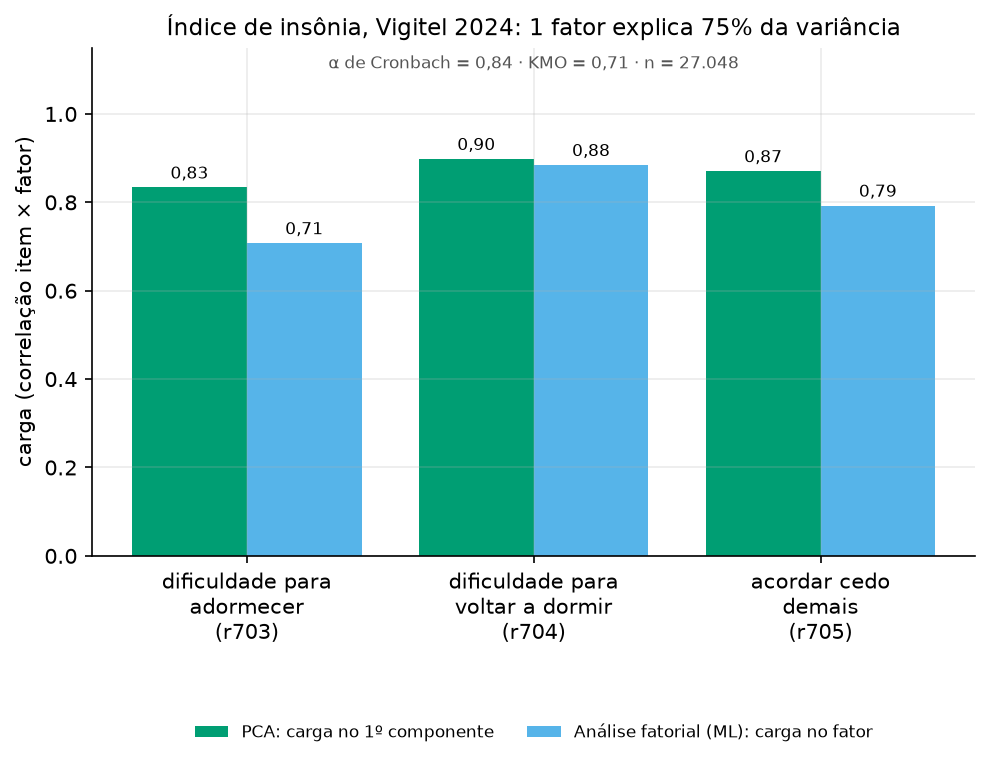

In [7]:
display(le_csv(TAB / "vigitel_indice.csv")[["variavel_vigitel", "pergunta_dicionario", "carga_pc1", "carga_af1_ml",
                                            "comunalidade_af1", "msa", "alfa_sem_item"]])
display(Image(filename=str(FIG / "cargas_insonia_vigitel.png")))

## Os conjuntos de itens da spec 002

In [8]:
ad = le_csv(TAB / "adequacao.csv")
ad[["conjunto", "n", "p", "lambda1", "var_pc1", "k_kaiser", "k_paralela"]]

,conjunto,n,p,lambda1,var_pc1,k_kaiser,k_paralela
0,insonia3_vigitel,27048,3,2.261,0.754,1,1
1,phq9_pns,88531,9,4.349,0.483,1,1
2,sassv_xuzhou,2317,10,4.784,0.478,2,2
3,doomscrolling_turquia,1216,15,8.750,0.583,1,1
4,procrastinacao_turquia,1216,9,3.669,0.408,2,2
5,ais_japao,381,8,4.690,0.586,1,1
6,bps_japao,381,9,3.822,0.425,2,2


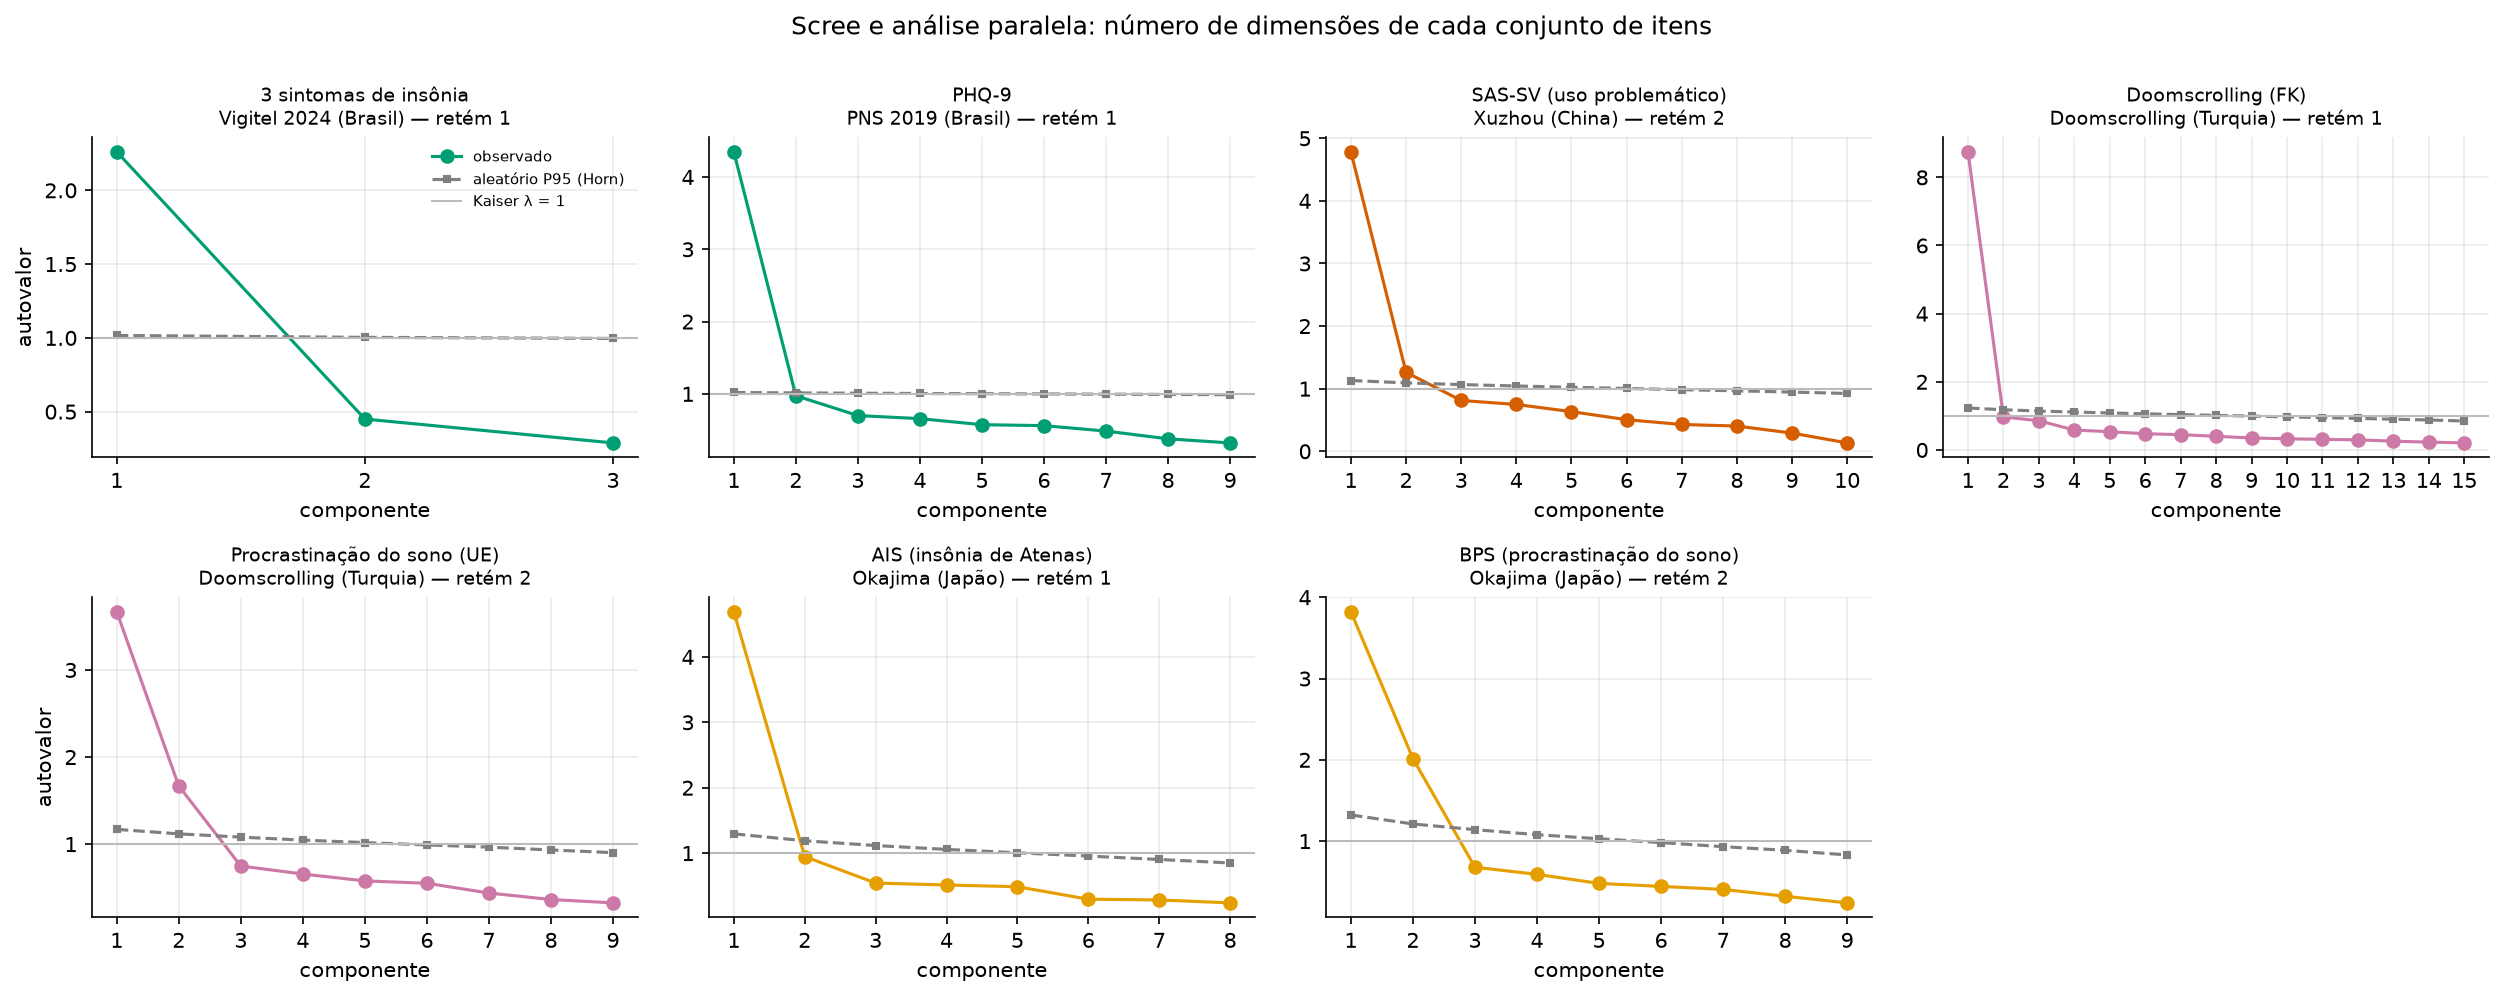

In [9]:
display(Image(filename=str(FIG / "scree_todos.png")))

**Leitura.** A análise paralela retém 1 dimensão no índice de insônia do Vigitel, no PHQ-9 da PNS, no doomscrolling
(Turquia) e na AIS (Japão); retém 2 no SAS-SV (China), na procrastinação (Turquia) e no BPS (Japão).

## Biplot: PHQ-9 da PNS 2019

O biplot mostra, no plano dos 2 primeiros componentes, as **cargas** (setas) e os **escores** (pontos). O CP1 é
"sofrimento em geral" (todas as setas para a direita, 48% da variância); o CP2
separa os itens somáticos (sono, cansaço, apetite) dos afetivos (humor, fracasso, autolesão).

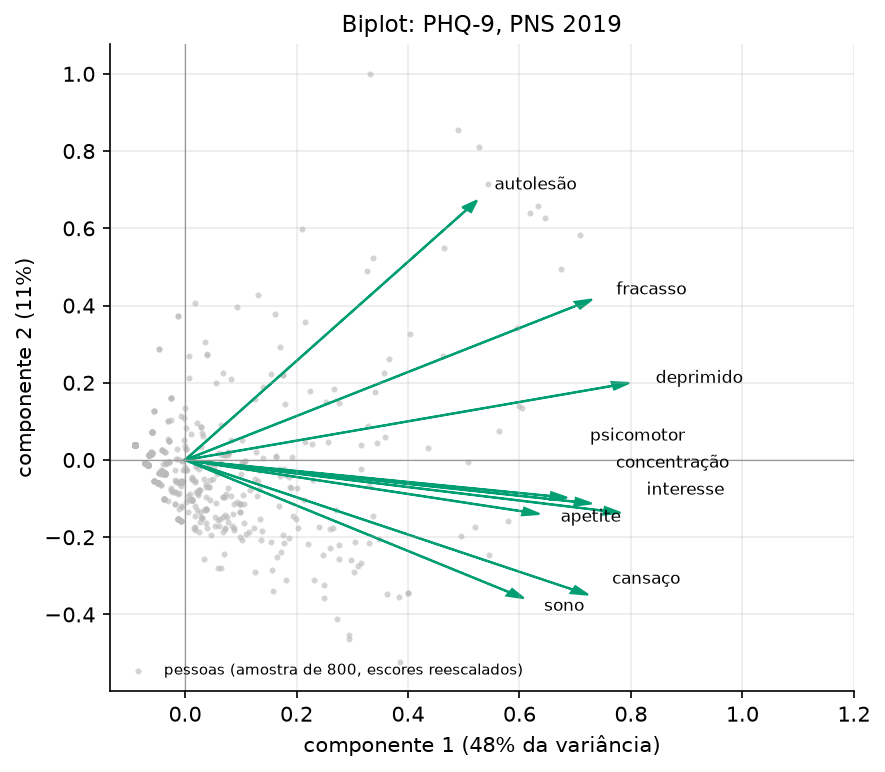

In [10]:
display(Image(filename=str(FIG / "biplot_phq9_pns.png")))

## Conclusão

- A PCA por SVD reproduz exatamente (até $10^{-8}$) a PCA de referência; os autovalores são $\sigma^2/(n-1)$.
- As 3 perguntas de insônia do Vigitel 2024 formam um componente dominante; a soma delas é o índice de insônia.
- O número de dimensões dos outros instrumentos está em `resultados/002/tabelas/adequacao.csv`; a análise
  fatorial (notebook 03) confirma e interpreta essas dimensões.